# Nextflow Pipeline Resource Analysis

Analyze Nextflow trace files to identify resource optimization opportunities
and compare resource usage across different pipeline runs.
## Workflow
1. **Load & Preprocess** — Import trace files and organize into comparison groups
2. **Optimization Analysis** — Identify processes with poor resource efficiency
3. **Process Consistency** — Filter to processes present across all runs
4. **Resource Analysis** — Compare scaling trends and per-process contributions


### Setup & Configuration

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from ipywidgets import Dropdown, interact

# Add project root to path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "workflow_helpers.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from workflow_helpers import (
    load_comparison_groups,
    identify_consistent_processes,
    create_optimization_bubble_chart,
    add_resource_hour_columns,
    RESOURCE_CONFIG,
    create_bubble,
    create_efficiency_bar,
    create_score_plot,
)

# Configure matplotlib styling
plt.style.use("seaborn-v0_8-dark")
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.15,
        "grid.linestyle": "-",
        "axes.titleweight": "medium",
        "axes.labelweight": "regular",
        "figure.dpi": 120,
    }
)

## 1. Load & Preprocess Trace Files
Organize trace files into comparison groups. Each group should contain runs
from the same pipeline that you want to compare.

In [2]:
# ── Configuration ──────────────────────────────────────────────────────────────
# Define comparison groups of trace files
comparison_groups = {
    "rnaseq": {
        "trace_files": [
            Path("../data/rnaseq_runs/rnaseq_test_trace_2026-03-19_16-41-59.txt"),
            Path("../data/rnaseq_runs/rnaseq_test_full_trace_2026-03-19_16-51-08.txt"),
        ],
        "labels": ["rnaseq test", "rnaseq test full"],  # or None for auto-labels
    },
}

# ── Load all trace files ───────────────────────────────────────────────────────
run_summary_df, process_df, trace_files, labels = load_comparison_groups(
    comparison_groups
)

Loading 1 comparison group(s):
  • rnaseq: 2 trace file(s)

Loading rnaseq:
  • rnaseq_test_trace_2026-03-19_16-41-59.txt
    → 219 completed tasks
  • rnaseq_test_full_trace_2026-03-19_16-51-08.txt
    → 303 completed tasks
⚠️  WARNING: 19 tasks used more CPU cores than requested!
   Scheduler may not be enforcing CPU limits properly.
   Examples (showing up to 5):
     NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:BAM_SORT_STATS_SAMTOOLS:BAM_STATS_SAMTOOLS:SAMTOOLS_STATS: requested 1.0 cores, used 1.3 (130.5%)
     NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:BAM_SORT_STATS_SAMTOOLS:BAM_STATS_SAMTOOLS:SAMTOOLS_STATS: requested 1.0 cores, used 1.2 (124.9%)
     NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:BAM_SORT_STATS_SAMTOOLS:BAM_STATS_SAMTOOLS:SAMTOOLS_STATS: requested 1.0 cores, used 1.2 (122.2%)
     NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:BAM_SORT_STATS_SAMTOOLS:BAM_STATS_SAMTOOLS:SAMTOOLS_STATS: requested 1.0 cores, used 1.3 (126.9%)
     NFCORE_RNASEQ:RNASEQ:BEDTOOLS_GENOMECOV_REV: requested 1.0 cores, used 1.1 (106.4%)




## 2. Optimization Analysis

Identify processes with poor CPU and memory efficiency. Bubble size reflects
computational burden (runtime × task count); color shows overall efficiency.
Top-right processes are highest-priority optimization targets.


In [3]:
def show_efficiency_dashboard(run_label, sort_by):
    """Show efficiency chart for a given run with chosen sorting."""
    idx = labels.index(run_label)
    stem = trace_files[idx].stem
    metrics = process_df[
        (process_df["filename"] == stem) & process_df["total_waste"].notna()
    ].copy()

    display(create_efficiency_bar(metrics, sort_by=sort_by))


interact(
    show_efficiency_dashboard,
    run_label=Dropdown(options=labels, description="Run:"),
    sort_by=Dropdown(
        options=[
            ("Avg CPU Efficiency", "avg_cpu_efficiency"),
            ("Avg Memory Efficiency", "avg_mem_efficiency"),
            ("Avg Time Efficiency", "avg_time_efficiency"),
            ("Sum of Efficiencies", "efficiency_sum"),
            ("Total Runtime", "total_runtime_hours"),
        ],
        description="Sort by:",
    ),
)

interactive(children=(Dropdown(description='Run:', options=('rnaseq test', 'rnaseq test full'), value='rnaseq …

<function __main__.show_efficiency_dashboard(run_label, sort_by)>

In [4]:
def show_optimization_analysis(run_label):
    """Display optimization bubble chart for selected run."""
    idx = labels.index(run_label)
    stem = trace_files[idx].stem
    metrics = process_df[
        (process_df["filename"] == stem) & process_df["total_waste"].notna()
    ].sort_values("total_waste", ascending=False)

    fig = create_optimization_bubble_chart(
        metrics, title=f"🎯 Process Optimization Opportunities — {run_label}"
    )
    fig.show()


interact(
    show_optimization_analysis,
    run_label=Dropdown(options=labels, description="Run:"),
)

interactive(children=(Dropdown(description='Run:', options=('rnaseq test', 'rnaseq test full'), value='rnaseq …

<function __main__.show_optimization_analysis(run_label)>

### Top Optimization Candidates (Tables)

In [5]:
# Display top 10 processes with highest waste for each run
display_cols = [
    "process_display",
    "n_tasks",
    "avg_cpus_requested",
    "avg_mem_requested_gb",
    "avg_cpu_efficiency",
    "avg_mem_efficiency",
    "overall_efficiency",
    "total_cpu_hours_wasted",
    "total_mem_gb_hours_wasted",
    "total_waste",
]

for run_label, trace_file in zip(labels, trace_files):
    metrics = process_df[
        (process_df["filename"] == trace_file.stem) & process_df["total_waste"].notna()
    ].sort_values("total_waste", ascending=False)

    top_n = metrics.head(10)[display_cols].copy()
    top_n[top_n.select_dtypes(include=[np.number]).columns] = top_n.select_dtypes(
        include=[np.number]
    ).round(2)

    print(f"\n🏆 Top optimization candidates — {run_label}\n")
    display(top_n)


🏆 Top optimization candidates — rnaseq test



,process_display,n_tasks,avg_cpus_requested,avg_mem_requested_gb,avg_cpu_efficiency,avg_mem_efficiency,overall_efficiency,total_cpu_hours_wasted,total_mem_gb_hours_wasted,total_waste
35,DUPRADAR,5.0,1.0,6.0,71.14,3.79,24.98,0.00,0.03,100.04
14,STAR_ALIGN,5.0,12.0,72.0,8.86,3.53,4.15,0.48,3.07,87.82
36,...ESS:BBMAP_BBSPLIT,5.0,12.0,72.0,42.92,3.05,15.33,0.14,1.43,82.82
40,TRIMGALORE,5.0,12.0,72.0,9.79,0.36,3.39,0.16,1.04,82.58
48,QUALIMAP_RNASEQ,5.0,6.0,36.0,17.09,0.57,5.89,0.04,0.28,40.66
18,...RD_MARKDUPLICATES,5.0,6.0,36.0,28.09,24.27,17.46,0.04,0.25,40.65
26,...C_READDUPLICATION,5.0,6.0,36.0,14.44,0.16,4.87,0.02,0.14,40.32
23,...UNCTIONANNOTATION,5.0,6.0,36.0,14.11,0.08,4.73,0.02,0.12,40.28
24,...UNCTIONSATURATION,5.0,6.0,36.0,15.17,0.17,5.11,0.02,0.11,40.27
22,RSEQC_INNERDISTANCE,5.0,6.0,36.0,13.77,0.13,4.63,0.02,0.11,40.27



🏆 Top optimization candidates — rnaseq test full



,process_display,n_tasks,avg_cpus_requested,avg_mem_requested_gb,avg_cpu_efficiency,avg_mem_efficiency,overall_efficiency,total_cpu_hours_wasted,total_mem_gb_hours_wasted,total_waste
71,STAR_ALIGN_IGENOMES,8.0,12.0,72.0,47.51,49.74,34.05,39.43,226.75,742.81
94,TRIMGALORE,8.0,12.0,72.0,57.70,1.74,20.95,22.20,308.83,654.45
75,...RD_MARKDUPLICATES,8.0,6.0,36.0,16.79,73.39,32.81,26.41,49.10,371.91
99,QUALIMAP_RNASEQ,8.0,6.0,36.0,15.62,25.04,15.54,19.28,102.56,355.51
83,...C_READDUPLICATION,8.0,6.0,36.0,15.68,45.46,21.68,12.65,46.73,234.73
92,DUPRADAR,8.0,1.0,6.0,87.61,7.50,32.33,0.39,16.61,177.56
82,..._READDISTRIBUTION,8.0,6.0,36.0,15.43,2.98,6.79,6.38,44.01,170.55
81,...UNCTIONSATURATION,8.0,6.0,36.0,15.89,3.70,7.18,6.35,43.44,169.68
77,RSEQC_BAMSTAT,8.0,6.0,36.0,15.04,0.14,5.66,5.84,41.23,162.43
80,...UNCTIONANNOTATION,8.0,6.0,36.0,14.37,0.41,5.50,5.62,39.18,158.27


## Step 3 — Process Consistency Check

Identify processes that do not appear in every run and exclude them. This ensures all comparisons are made on a consistent set of processes.


In [6]:
# Mark consistent processes per group
process_df["is_consistent"] = False

for group_name, group_config in comparison_groups.items():
    group_trace_files = group_config["trace_files"]
    group_labels_local = group_config.get("labels")

    # Use filenames if no labels provided
    if not group_labels_local or len(group_labels_local) != len(group_trace_files):
        group_labels_local = [f.stem for f in group_trace_files]

    group_filenames = [f.stem for f in group_trace_files]
    group_process_df = process_df[process_df["group"] == group_name]

    if len(group_trace_files) == 1:
        print(f"Group: {group_name}")
        print(
            f"  Single run — all {len(group_process_df['process'].unique())} "
            "processes marked as consistent."
        )
        process_df.loc[process_df["group"] == group_name, "is_consistent"] = True
        print()
    else:
        print(f"Group: {group_name}")
        print(
            f"  Comparing {len(group_trace_files)} runs: {', '.join(group_labels_local)}"
        )

        consistent_procs = identify_consistent_processes(
            group_process_df, group_filenames, group_labels_local, verbose=True
        )

        mask = (process_df["group"] == group_name) & (
            process_df["process"].isin(consistent_procs)
        )
        process_df.loc[mask, "is_consistent"] = True
        print()

print(
    f"\n✓ Process consistency analysis complete for "
    f"{len(comparison_groups)} group(s)."
)

Group: rnaseq
  Comparing 2 runs: rnaseq test, rnaseq test full
  EXCLUDED — processes not present in all 2 run(s):
──────────────────────────────────────────────────────────────────────
  • NFCORE_RNASEQ:PREPARE_GENOME:BBMAP_BBSPLIT
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:CUSTOM_CATADDITIONALFASTA
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GTF2BED
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GUNZIP_ADDITIONAL_FASTA
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GUNZIP_GTF
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:MAKE_TRANSCRIPTS_FASTA
    Found in: rnaseq test full
  • NFCORE_RNASEQ:PREPARE_GENOME:SALMON_INDEX
    Found in: rnaseq test full
  • NFCORE_RNASEQ:PREPARE_GENOME:STAR_GENOMEGENERATE
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:UNTAR_SALMON_INDEX
    Found in: rnaseq test
  • NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:STAR_ALIGN
    Found in: rnaseq test
  • NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:STAR_

## 4. Resource Analysis

### 4.1 Resource Scaling Trends

Visualize how total CPU, memory, and I/O usage scales across runs.

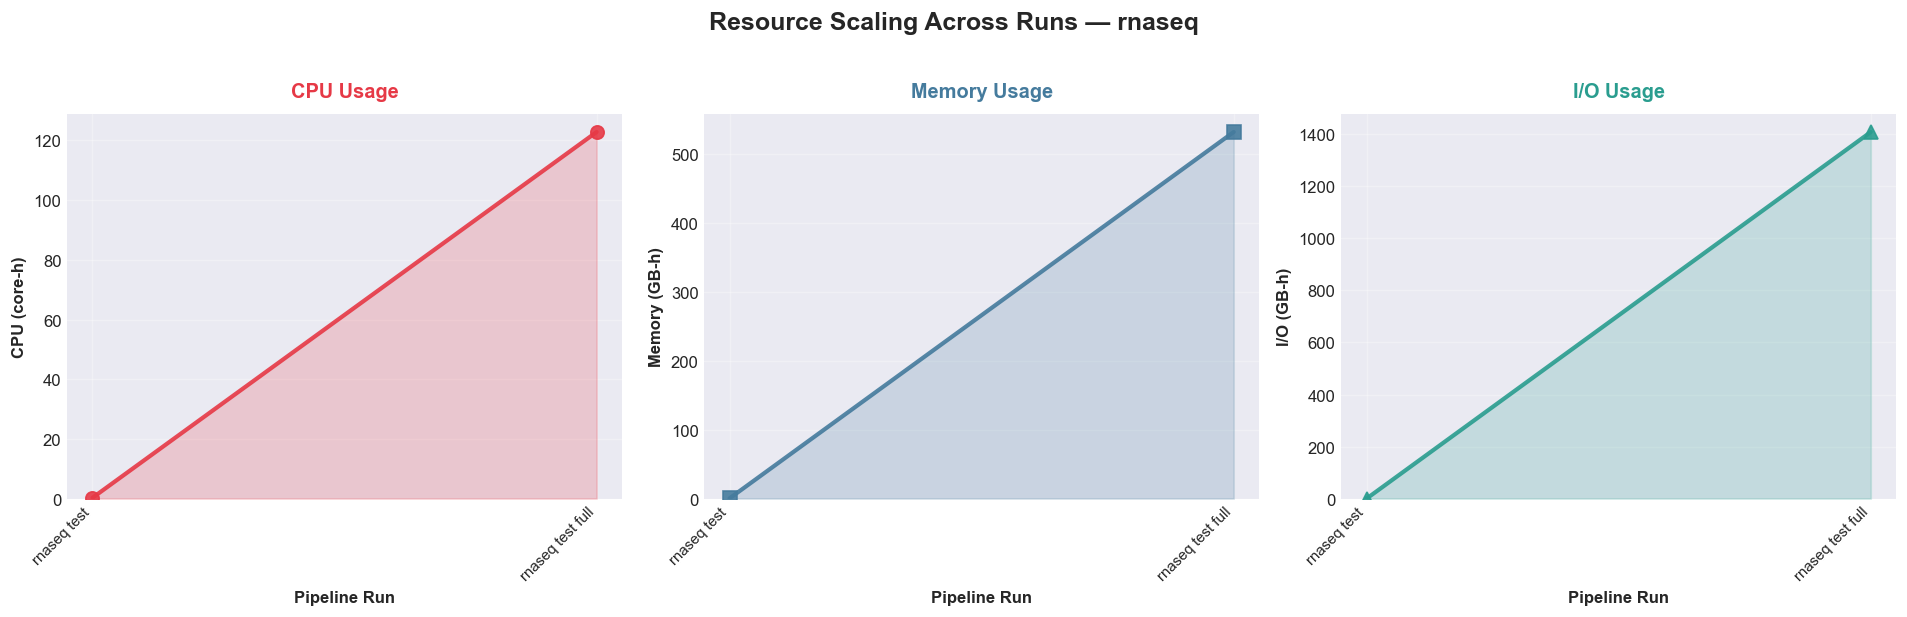

In [7]:
def plot_resource_scaling(group_name):
    """Plot resource scaling trends for selected group."""
    group_run_df = run_summary_df[run_summary_df["group"] == group_name].copy()
    group_labels_list = group_run_df["label"].tolist()
    x_pos = np.arange(len(group_run_df))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(
        f"Resource Scaling Across Runs — {group_name}",
        fontsize=15,
        fontweight="bold",
        y=1.02,
    )

    for i, resource in enumerate(["CPU", "Memory", "I/O"]):
        cfg = RESOURCE_CONFIG[resource]
        y = cfg["convert"](group_run_df[cfg["time_col"]].values)

        ax = axes[i]
        ax.plot(
            x_pos,
            y,
            marker=cfg["marker"],
            linewidth=2.5,
            markersize=8,
            color=cfg["color"],
            alpha=0.9,
        )
        ax.fill_between(x_pos, 0, y, color=cfg["color"], alpha=0.2)
        ax.set_ylabel(cfg["ylabel"], fontweight="bold")
        ax.set_xlabel("Pipeline Run", fontweight="bold")
        ax.set_title(
            f"{resource} Usage",
            fontsize=12,
            pad=10,
            color=cfg["color"],
            fontweight="bold",
        )
        ax.set_xticks(x_pos)
        ax.set_xticklabels(group_labels_list, rotation=45, ha="right", fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim(bottom=0)

    plt.tight_layout()
    plt.show()


group_options = list(comparison_groups.keys())

if len(group_options) > 1:
    interact(
        plot_resource_scaling,
        group_name=Dropdown(options=group_options, description="Group:"),
    )
else:
    plot_resource_scaling(group_options[0])

### 4.2 Per-Process Resource Composition

Compare CPU, memory, and I/O contributions across top processes for each run.

In [8]:
TOP_N_PROCESSES = 15


def plot_process_composition(run_label, sort_by):
    """Display per-process resource bar chart."""
    idx = labels.index(run_label)
    pp = process_df[process_df["filename"] == trace_files[idx].stem].copy()
    pp = add_resource_hour_columns(pp)
    pp = pp.nlargest(TOP_N_PROCESSES, sort_by).sort_values(sort_by, ascending=False)

    x = np.arange(len(pp))
    width = 0.25

    figsize = (max(10, len(pp) * 0.45), 6)
    fig, ax = plt.subplots(figsize=figsize)

    for i, resource in enumerate(["CPU", "Memory", "I/O"]):
        cfg = RESOURCE_CONFIG[resource]
        ax.bar(
            x + (i - 1) * width,
            pp[f"{resource.lower()}_h"].values,
            width,
            color=cfg["color"],
            alpha=0.9,
            label=cfg["ylabel"],
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        pp["process_display"].values, fontsize=9, rotation=45, ha="right"
    )
    ax.set_ylabel("Resource Contribution (hours)", fontweight="bold")
    ax.set_title(
        f"Per-Process Resource Contribution — {run_label} (sorted by {sort_by})",
        fontsize=13,
        pad=10,
    )
    ax.legend(loc="upper right", framealpha=0.95, fontsize=10)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


sort_options = [
    ("Total (CPU+Memory+I/O)", "total_h"),
    ("CPU", "cpu_h"),
    ("Memory", "memory_h"),
    ("I/O", "i/o_h"),
]

interact(
    plot_process_composition,
    run_label=Dropdown(options=labels, description="Run:"),
    sort_by=Dropdown(options=sort_options, description="Sort by:"),
)

interactive(children=(Dropdown(description='Run:', options=('rnaseq test', 'rnaseq test full'), value='rnaseq …

<function __main__.plot_process_composition(run_label, sort_by)>

### 4.3 Process Scaling Explorer (Interactive)

Scaling curves per process for the top contributors per resource type.
Use buttons to switch between CPU, Memory, and I/O views.
Click processes in the legend to show/hide them.

In [9]:
TOP_PROCESSES_PER_RESOURCE = 15


def create_scaling_explorer(group_name):
    """Create interactive process scaling explorer for a specific comparison group."""
    # Filter to only consistent processes of this group
    group_process_df = process_df[
        (process_df["group"] == group_name) & (process_df["is_consistent"])
    ].copy()

    if group_process_df.empty:
        print(f"No consistent processes found for {group_name}")
        return

    # Get the run labels for this group
    group_run_df = run_summary_df[run_summary_df["group"] == group_name]
    group_labels_list = group_run_df["label"].tolist()

    # Add converted columns
    long_df = group_process_df.copy()
    long_df["run_label"] = long_df["label"]
    long_df["cpu_contrib_h"] = long_df["cpu_contrib"] / (1000 * 3600)
    long_df["mem_contrib_h"] = long_df["mem_contrib"] / (1024**3 * 1000 * 3600)
    long_df["io_contrib_h"] = long_df["io_contrib"] / (1024**3 * 1000 * 3600)

    run_order = {lbl: i for i, lbl in enumerate(group_labels_list)}
    long_df["run_idx"] = long_df["run_label"].map(run_order)

    # Identify top processes per resource
    top_cpu = (
        long_df.groupby("process")["cpu_contrib_h"]
        .sum()
        .nlargest(TOP_PROCESSES_PER_RESOURCE)
        .index.tolist()
    )
    top_mem = (
        long_df.groupby("process")["mem_contrib_h"]
        .sum()
        .nlargest(TOP_PROCESSES_PER_RESOURCE)
        .index.tolist()
    )
    top_io = (
        long_df.groupby("process")["io_contrib_h"]
        .sum()
        .nlargest(TOP_PROCESSES_PER_RESOURCE)
        .index.tolist()
    )

    # Assign stable colors
    import plotly.colors

    palette = plotly.colors.qualitative.Dark24 + plotly.colors.qualitative.Light24
    all_procs = list(dict.fromkeys(top_cpu + top_mem + top_io))
    proc_color = {p: palette[i % len(palette)] for i, p in enumerate(all_procs)}

    # Build display name lookup
    proc_display = {}
    for proc in all_procs:
        row = long_df[long_df["process"] == proc]
        if not row.empty:
            proc_display[proc] = row["process_display"].iloc[0]

    resource_config = [
        ("CPU", top_cpu, "cpu_contrib_h", "CPU contribution (hours)"),
        ("Memory", top_mem, "mem_contrib_h", "Memory contribution (hours)"),
        ("I/O", top_io, "io_contrib_h", "I/O contribution (hours)"),
    ]

    fig = go.Figure()
    trace_ranges = {}

    for resource, procs, metric, _ in resource_config:
        start = len(fig.data)
        is_first_resource = resource == "CPU"
        legend_shown_for_resource = set()

        for proc in procs:
            subset = long_df[long_df["process"] == proc].sort_values("run_idx")
            if subset.empty:
                continue

            display_name = proc_display.get(proc, proc)
            color = proc_color.get(proc, "#888888")

            show_in_legend = display_name not in legend_shown_for_resource
            if show_in_legend:
                legend_shown_for_resource.add(display_name)

            customdata = [
                [row.cpu_contrib_h, row.mem_contrib_h, row.io_contrib_h, row.run_label]
                for row in subset.itertuples()
            ]

            rc = RESOURCE_CONFIG["CPU"]["color"]
            mc = RESOURCE_CONFIG["Memory"]["color"]
            ic = RESOURCE_CONFIG["I/O"]["color"]

            hovertemplate = (
                f"<b>{display_name}</b><br>"
                "<i>%{customdata[3]}</i><br><br>"
                f"<b style='color:{rc}'>CPU</b>      %{{customdata[0]:.3f}} h<br>"
                f"<b style='color:{mc}'>Memory</b>   %{{customdata[1]:.3f}} h<br>"
                f"<b style='color:{ic}'>I/O</b>      %{{customdata[2]:.3f}} h<br>"
                "<extra></extra>"
            )

            fig.add_trace(
                go.Scatter(
                    x=subset["run_label"].tolist(),
                    y=subset[metric].tolist(),
                    mode="lines+markers",
                    name=display_name,
                    legendgroup=f"{resource}_{display_name}",
                    showlegend=show_in_legend,
                    customdata=customdata,
                    hovertemplate=hovertemplate,
                    marker=dict(
                        size=10,
                        color=color,
                        line=dict(width=2, color="white"),
                        symbol="circle",
                    ),
                    line=dict(width=2.5, color=color),
                    visible=is_first_resource,
                )
            )

        trace_ranges[resource] = (start, len(fig.data))

    total_traces = len(fig.data)

    def vis_list(active_resource):
        result = [False] * total_traces
        s, e = trace_ranges[active_resource]
        for i in range(s, e):
            result[i] = True
        return result

    buttons = [
        dict(
            label=f" {res} ",
            method="update",
            args=[
                {"visible": vis_list(res)},
                {
                    "yaxis.title.text": ytitle,
                    "title.text": f"Process Scaling Explorer — {group_name} — Top {TOP_PROCESSES_PER_RESOURCE} by {res}",
                },
            ],
        )
        for res, _, _, ytitle in resource_config
    ]

    fig.update_layout(
        title=dict(
            text=f"Process Scaling Explorer — {group_name} — Top {TOP_PROCESSES_PER_RESOURCE} by CPU",
            font=dict(size=16, color="#1a1a2e", family="sans-serif"),
            x=0,
            xanchor="left",
            pad=dict(l=4, b=10),
        ),
        updatemenus=[
            dict(
                type="buttons",
                direction="right",
                x=0.0,
                xanchor="left",
                y=1.0,
                yanchor="bottom",
                pad=dict(r=6, t=6, b=6),
                buttons=buttons,
                showactive=True,
                bgcolor="#f2f4f8",
                bordercolor="#c8cdd6",
                borderwidth=1,
                font=dict(size=12, color="#222"),
                active=0,
            )
        ],
        xaxis=dict(
            title=dict(text="Pipeline Run", font=dict(size=12, color="#333")),
            tickfont=dict(size=11, color="#333"),
            showgrid=False,
            linecolor="#c8cdd6",
            linewidth=1,
            showline=True,
            ticks="outside",
            ticklen=5,
        ),
        yaxis=dict(
            title=dict(
                text="CPU contribution (hours)", font=dict(size=12, color="#333")
            ),
            tickfont=dict(size=10, color="#333"),
            gridcolor="#e4e9f0",
            gridwidth=1,
            zeroline=False,
            linecolor="#c8cdd6",
            linewidth=1,
            showline=True,
        ),
        hovermode="closest",
        hoverlabel=dict(
            bgcolor="#e8edf3",
            bordercolor="#c8cdd6",
            font=dict(size=11, color="#2d3436"),
            namelength=0,
        ),
        height=580,
        width=1100,
        plot_bgcolor="#f7f9fc",
        paper_bgcolor="white",
        legend=dict(
            title=dict(text="Process", font=dict(size=10, color="#444")),
            font=dict(size=9, color="#222"),
            bgcolor="rgba(255,255,255,0.97)",
            bordercolor="#c8cdd6",
            borderwidth=1,
            groupclick="togglegroup",
            itemsizing="constant",
            tracegroupgap=1,
            x=1.01,
            xanchor="left",
            y=1,
            yanchor="top",
        ),
        margin=dict(t=110, r=240, l=60, b=70),
    )

    fig.show()


if len(group_options) > 1:
    interact(
        create_scaling_explorer,
        group_name=Dropdown(options=group_options, description="Group:"),
    )
else:
    create_scaling_explorer(group_options[0])